# 抓杯子：确定性动作模型的完整训练与评估

首轮40条数据、5000次训练更新和30回合评估已完整完成，物理成功2/30。两条训练场景闭环诊断为1/2；对两个失败场景逐步重规划仍为0/2。归一化、参数完整加载及采集／回放观测已分别核对。

本篇复用首轮40条已全部物理回放通过的数据，独立训练不使用 VAE［变分自编码器］的 ACT［动作分块变换器］，执行20000次更新及同一组30个未见种子的完整评估。数据迭代器每轮重新取批，重新打乱并刷新图像增强；源码、配方和结果与首轮分别保存。这轮同时改变模型隐变量设置和训练长度，结果用于比较完整配方的闭环效果。

默认读取已保存证据；设置 `AMD_RUN_FULL=1` 可实际执行完整流程。采集及回放单元验证并复用已有数据，不重新采集，不把复用计为新采集。


## 环境、输入与输出

复用已安装的 ROCm［AMD异构计算平台］训练环境与匹配的旧版 LeRobot 代码。仿真资产取自原抓杯子工程的 `asset` 文件夹。结果目录独立保存数据、日志、新权重和视频；课程目录保存轻量结果快照。

| 参数 | 本篇配方 |
|---|---|
| 采集随机种子 | 1000–1039，共40次尝试，只保存物理成功演示 |
| 训练 | 20000次更新，批量8，梯度累积1，有效批量8，学习率0.0001 |
| 初始化 | 缓存的视觉骨干；动作变换器随机初始化；优化全部可训练参数 |
| 输入与输出 | 两路图像、末端位姿 → 六关节目标与夹爪命令 |
| 动作块 | 20步；控制频率20赫兹 |
| 评估 | 2000–2029，共30回合，每回合最多1200控制步 |
| 物理成功 | 至少抬升6厘米并保持3步，杯子放到盘上、松爪，最终直立余弦≥0.85 |

开始前至少保留12 GiB［二进制吉字节］磁盘空间。统一内存峰值由真实训练日志记录。脚本专家会读取物体位置用于采集；学习策略不读取物体真值，也不使用回放动作或专家纠正。

复现前设置 `CUP_BASELINE_RUN` 为首轮完整实验目录；迁移助手逐文件核对40条已物理回放成功的数据，只复用输入与回放证据。新目录从头训练20000步并执行30回合评估；已有目录仅核验后继续，配方或数据指纹不匹配时停止。


In [1]:
from pathlib import Path
import os, sys, json, subprocess
from IPython.display import display, Markdown, HTML, Image
TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/cup_pipeline_deterministic/course_run.py").is_file())
SOURCE = Path(os.environ.get("CUP_SOURCE_DIR", str(TOPIC / "code/cup_pipeline_deterministic"))).resolve()
RUN_FULL = os.environ.get("AMD_RUN_FULL", "0") == "1"
RUN = Path(os.environ.get("CUP_RUN_ROOT", "/data/Data14TB/runs/every_embodied/cup-deterministic-v2"))
SNAPSHOT = TOPIC / "notebooks/results/cup-deterministic-v2"
print({"完整执行": RUN_FULL, "源码": str(SOURCE), "实验目录": str(RUN)})
if RUN_FULL:
    for key in ("EXPERIMENT_PYTHON", "LEROBOT_SRC", "PNP_ASSET_ROOT"):
        assert os.environ.get(key), f"需要设置 {key}"
    assert Path(os.environ["EXPERIMENT_PYTHON"]).is_file()
    # Verify or initialize the reused inputs before any heavy stage.
    baseline = Path(os.environ.get("CUP_BASELINE_RUN", "/data/Data14TB/01Proj/every-embodied-amd/cup-full-20261027-v1"))
    subprocess.run([os.environ["EXPERIMENT_PYTHON"], str(TOPIC / "code/prepare_cup_refinement.py"),
                    "--source-run", str(baseline), "--target-run", str(RUN),
                    "--source-code", str(SOURCE), "--assets", os.environ["PNP_ASSET_ROOT"]], check=True)
    SOURCE = RUN / "source"
    os.environ["CUP_RUN_ROOT"] = str(RUN)
def stage(name):
    if RUN_FULL:
        subprocess.run([os.environ["EXPERIMENT_PYTHON"], str(SOURCE / "course_run.py"), name], check=True)
    else:
        state_file = SNAPSHOT / "pipeline_state.json"
        state = json.loads(state_file.read_text()) if state_file.exists() else {"status": "等待本次实训完成"}
        display(Markdown("```json\n" + json.dumps(state.get("completed", {}).get(name, state), ensure_ascii=False, indent=2) + "\n```"))


{'完整执行': False, '源码': '/home/aup/amd-notebook-work/course/code/cup_pipeline_deterministic', '实验目录': '/data/Data14TB/runs/every_embodied/cup-deterministic-v2'}


## 1. 验证并复用采集数据

核验首轮40条物理成功演示的种子、帧数和数据内容指纹，复用已保存的数据。新运行目录保存输入迁移清单，不重新采集。

In [2]:
stage("collect")

```json
{
  "attempts": 40,
  "saved_episodes": 40,
  "frames": 15195
}
```

## 2. 核验全部物理回放证据

复用首轮40条轨迹全部通过的物理回放记录，并核对关联的数据文件。数据迁移只复用输入阶段，训练和评估从本轮实际执行。

In [3]:
stage("audit")

```json
{
  "repo_id": "amd_cup_red_v1",
  "root": "/home/aup/amd-notebook-work/cup-full-20261027-v1/dataset",
  "episodes": 40,
  "legacy_success_count": 40,
  "physical_success_count": 40,
  "legacy_success_rate": 1.0,
  "physical_success_rate": 1.0,
  "episode_indexes": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39
  ],
  "physical_min_lift": 0.06,
  "physical_min_lift_steps": 3,
  "physical_final_upright_cos": 0.85
}
```

## 3. 完整训练

执行20000次真实梯度更新，记录损失、耗时、设备、实际可训练参数和内存峰值。遇到非有限损失立即停止并保存日志；最终保存新权重及内容指纹。

In [4]:
stage("train")

```json
{
  "updates": 20000,
  "last_loss": 0.064675,
  "elapsed_s": 2179.8,
  "weights_sha256": "b0e1b0e740f1669ebfd1e709bd34f146ed8ae6475e9c1b6637098bf62a14537e"
}
```

## 4. 新权重完整闭环评估

在30个未参与采集的固定种子上运行学习策略，每回合保留双视角录像和轨迹。使用相同的新权重完成全部回合，并输出逐回合物理成功判定。

In [5]:
stage("evaluate")

```json
{
  "episodes": 30,
  "physical_successes": 3,
  "seeds": [
    2000,
    2001,
    2002,
    2003,
    2004,
    2005,
    2006,
    2007,
    2008,
    2009,
    2010,
    2011,
    2012,
    2013,
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022,
    2023,
    2024,
    2025,
    2026,
    2027,
    2028,
    2029
  ],
  "horizon": 1200,
  "weights_sha256": "b0e1b0e740f1669ebfd1e709bd34f146ed8ae6475e9c1b6637098bf62a14537e"
}
```

## 5. 最终训练曲线与逐回合结果

/home/aup/envs/robocasa365-rocm-py312/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


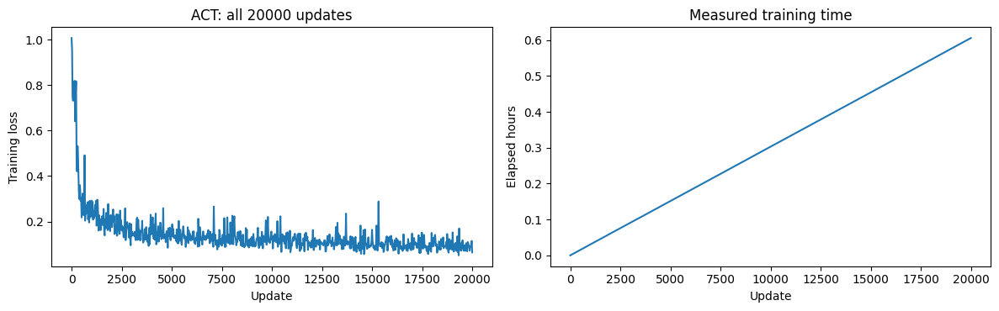

|种子|物理成功|控制步数|
|---|---|---|
|2000|False|1200|
|2001|False|1200|
|2002|True|1086|
|2003|False|1200|
|2004|False|1200|
|2005|False|1200|
|2006|False|1200|
|2007|True|310|
|2008|False|1200|
|2009|False|1200|
|2010|False|1200|
|2011|False|1200|
|2012|False|1200|
|2013|False|1200|
|2014|False|1200|
|2015|False|1200|
|2016|False|1200|
|2017|False|1200|
|2018|True|297|
|2019|False|1200|
|2020|False|1200|
|2021|False|1200|
|2022|False|1200|
|2023|False|1200|
|2024|False|1200|
|2025|False|1200|
|2026|False|1200|
|2027|False|1200|
|2028|False|1200|
|2029|False|1200|

```json
{
  "episodes": 30,
  "physical_successes": 3,
  "seeds": [
    2000,
    2001,
    2002,
    2003,
    2004,
    2005,
    2006,
    2007,
    2008,
    2009,
    2010,
    2011,
    2012,
    2013,
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022,
    2023,
    2024,
    2025,
    2026,
    2027,
    2028,
    2029
  ],
  "horizon": 1200,
  "weights_sha256": "b0e1b0e740f1669ebfd1e709bd34f146ed8ae6475e9c1b6637098bf62a14537e"
}

```

In [6]:
import matplotlib.pyplot as plt
EVIDENCE = RUN if RUN_FULL else SNAPSHOT
metrics_file = EVIDENCE / "training-metrics.json"
if metrics_file.exists():
    metrics = json.loads(metrics_file.read_text())
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot([r["step"] for r in metrics], [r["loss"] for r in metrics])
    axes[0].set(xlabel="Update", ylabel="Training loss", title="ACT: all 20000 updates")
    axes[1].plot([r["step"] for r in metrics], [r["elapsed_s"] / 3600 for r in metrics])
    axes[1].set(xlabel="Update", ylabel="Elapsed hours", title="Measured training time")
    fig.tight_layout(); display(fig); plt.close(fig)
    rows = [json.loads(s) for s in (EVIDENCE / "evaluation.jsonl").read_text().splitlines() if s.strip()]
    display(Markdown("|种子|物理成功|控制步数|\n|---|---|---|\n" + "\n".join(f"|{r['seed']}|{r['physical_success']}|{r.get('action_steps', '')}|" for r in rows)))
    display(Markdown("```json\n" + (EVIDENCE / "evaluation-summary.json").read_text() + "\n```"))
else:
    print("本次完整实验正在运行，最终曲线与30回合结果将在评估结束后保存。")


## 6. 本次成功与失败录像

预览和完整视频均来自本次正式评估；采集视频单独标注，不计入策略成功率。

复用的首轮脚本专家采集演示，种子1000；独立于学习策略评估

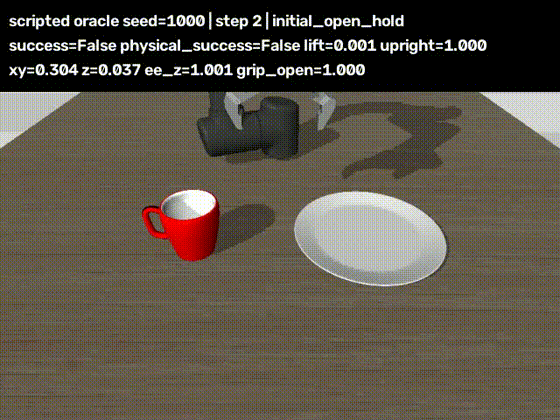

本次正式评估成功，种子2002

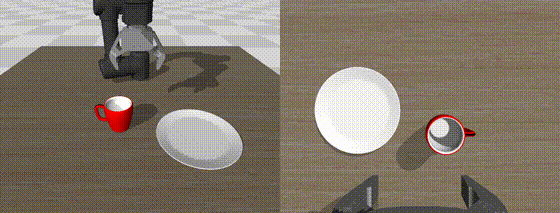

本次正式评估失败，种子2000

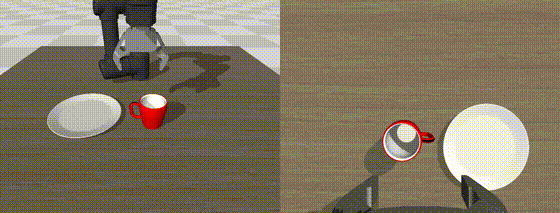

In [7]:
media_file = SNAPSHOT / "media.json"
if media_file.exists():
    for item in json.loads(media_file.read_text()):
        display(Markdown(item["label"]))
        display(Image(filename=str(SNAPSHOT / item["preview"])))
        relative = os.path.relpath(SNAPSHOT / item["video"], Path.cwd())
        display(HTML(f'<video controls preload="metadata" width="640" src="{relative}"></video>'))
else:
    print("等待本次正式评估录像；旧结果请查看抓杯子任务入口。")


## 固定专家观测的独立预测核查

沿用首轮相同的12个专家观测帧，本轮严格完整权重加载通过，12个夹爪开闭判断全部匹配；平均关节绝对误差由0.021805降至0.011734弧度。此处记录固定专家输入的预测精度，闭环成功率使用上方完整30回合结果。


In [8]:
comparison = json.loads((SNAPSHOT / "expert-prediction-comparison.json").read_text())
display(Markdown("```json\n" + json.dumps(comparison, ensure_ascii=False, indent=2) + "\n```"))


```json
{
  "scope": "Same 12 stored expert observations; separate from closed-loop evaluation",
  "comparison": [
    {
      "recipe": "first_5000",
      "strict_loading_passed": true,
      "observations": 12,
      "gripper_matches": 12,
      "mean_joint_mae_rad": 0.021804891630179353,
      "weights_sha256": "e332621cc67f5462990f21316847ec082d45fc911ef70264e6d0ed54124e39fc"
    },
    {
      "recipe": "deterministic_20000",
      "strict_loading_passed": true,
      "observations": 12,
      "gripper_matches": 12,
      "mean_joint_mae_rad": 0.011733849274201525,
      "weights_sha256": "b0e1b0e740f1669ebfd1e709bd34f146ed8ae6475e9c1b6637098bf62a14537e"
    }
  ]
}
```